In [79]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

In [80]:
#Reads in the data
df = pd.read_csv('calories_burned_data.csv', na_values='?')

In [81]:
#List out the column names
df.columns

Index(['Gender', 'Age', 'Height(cm)', 'Weight(kg)', 'BMI', 'Running Time(min)',
       'Running Speed(km/h)', 'Distance(km)', 'Average Heart Rate',
       'Calories Burned'],
      dtype='object')

In [82]:
#Showcase the first 5 rows to assess the look of the data. Initial review shows the adata is already in numeric variables
df.head(5)

,Gender,Age,Height(cm),Weight(kg),BMI,Running Time(min),Running Speed(km/h),Distance(km),Average Heart Rate,Calories Burned
0,Male,49,184,74,20.4,78,9.5,3.00,139,973
1,Female,56,182,70,23.2,98,10.2,5.23,165,494
2,Male,49,170,85,27.4,91,10.4,7.61,134,954
3,Male,21,181,59,24.0,89,13.4,14.19,144,570
4,Male,47,172,86,29.8,79,9.8,3.84,149,385


The data takes both Male and Females running statistics and shows how many calories are burned. My target variable will be
the Gender column and my prediction goal is to predict who will burn more calories a Male or Female based on the data presented.

In [83]:
#Look at the data to see if there are any null values. No null values indicated
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               200 non-null    object 
 1   Age                  200 non-null    int64  
 2   Height(cm)           200 non-null    int64  
 3   Weight(kg)           200 non-null    int64  
 4   BMI                  200 non-null    float64
 5   Running Time(min)    200 non-null    int64  
 6   Running Speed(km/h)  200 non-null    float64
 7   Distance(km)         200 non-null    float64
 8   Average Heart Rate   200 non-null    int64  
 9   Calories Burned      200 non-null    int64  
dtypes: float64(3), int64(6), object(1)
memory usage: 15.8+ KB


In [84]:
#Drop any duplicates
df = df.drop_duplicates()

In [85]:
#Rename the Gender column to the target variable
df = df.rename(columns={'Gender': 'Target'})

In [86]:
#Give the target variable a numeric label, 0 signifying Males and 1 signifying Females
df['Target'] = df['Target'].replace({'Male': 0, 'Female': 1})

C:\Users\local_eharmon4\Temp\ipykernel_11348\1347522047.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Target'] = df['Target'].replace({'Male': 0, 'Female': 1})


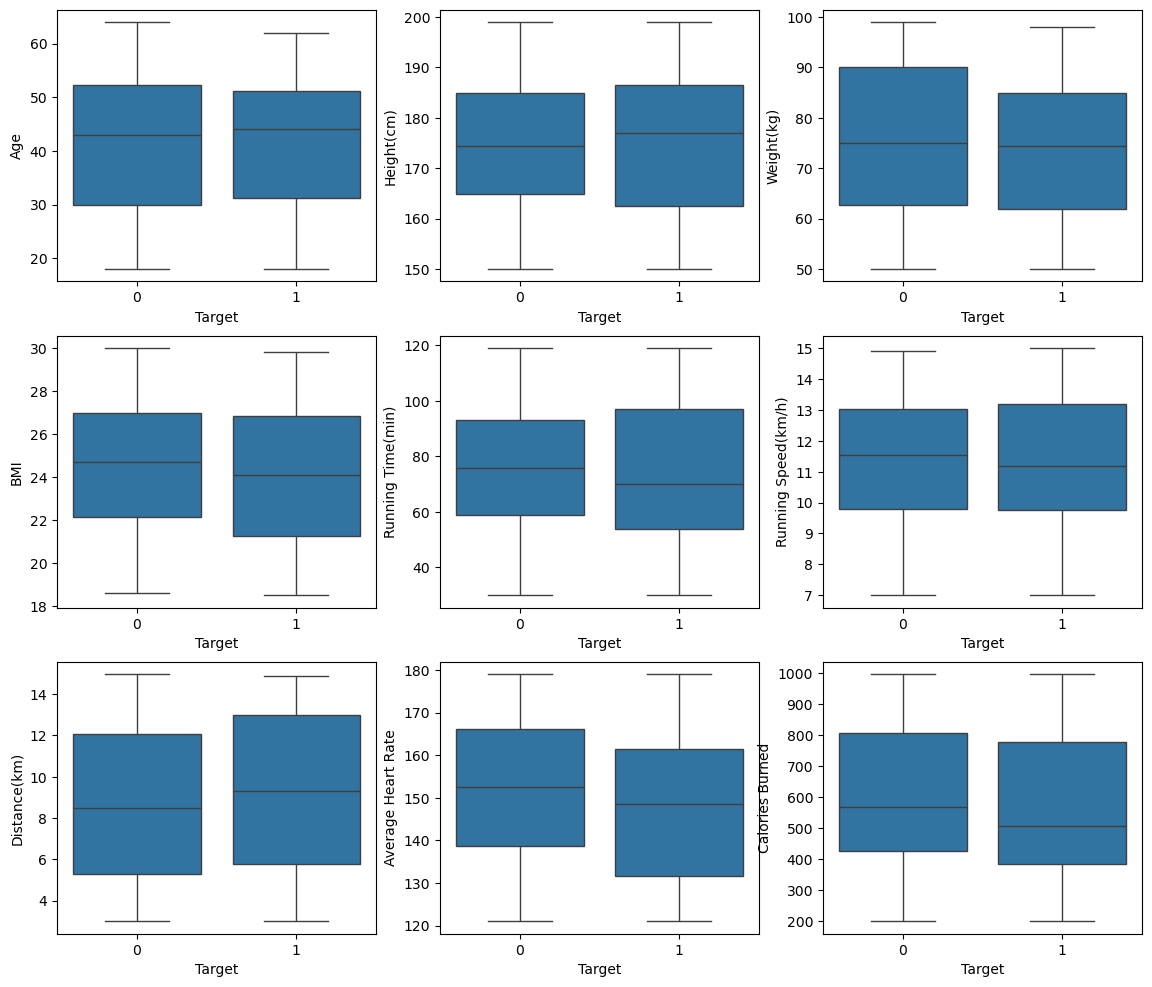

In [87]:
#Numeric Boxplot to compare values to target and look for outliers
import seaborn as sns
import matplotlib.pyplot as plt
num_list=['Age', 'Height(cm)', 'Weight(kg)', 'BMI', 'Running Time(min)', 'Running Speed(km/h)', 'Distance(km)', 'Average Heart Rate', 'Calories Burned' ]
fig=plt.figure(figsize=(14, 12))

for i in range(len(num_list)):
    column=num_list[i]
    sub=fig.add_subplot(3,3,i+1)
    sns.boxplot(x='Target',y=column, data=df)

In [88]:
# ANOVA test to evaluate fscores and pvalues
from sklearn.feature_selection import SelectKBest, f_classif
x = df.loc[:, ['Age', 'Height(cm)', 'Weight(kg)', 'BMI', 'Running Time(min)', 'Running Speed(km/h)', 
               'Distance(km)', 'Average Heart Rate', 'Calories Burned']]
y = df.loc[:, 'Target']

fs = SelectKBest(score_func=f_classif, k='all')  # call the method
FeaturesS = fs.fit(x, y)    # train the model
np.set_printoptions(suppress = True)
print(FeaturesS.scores_)    # print out the scores 
print()
print(FeaturesS.pvalues_)



[0.07400173 0.14503299 0.71660641 0.73679107 0.18364869 0.60656899
 0.74434462 3.83341244 1.81869608]

[0.78588042 0.70373622 0.39828129 0.39172865 0.66872202 0.43701237
 0.38931647 0.0516455  0.17900906]


In [89]:
#Use Average Heart Rate and Calories burned for features, due to these features having the highest F score, although it is very low
#Drop other features due to low variance and irrelvance to the target variable
#Drop 'Age', 'Height(cm)', 'Weight(kg)', 'BMI', 'Running Time(min)', 'Running Speed(km/h)', Distance(km)
#There are no categorical variables that need to be changed to dummy variables due to the features not having more than 2 classes

In [90]:
#Correlation between the data
df.corr()

,Target,Age,Height(cm),Weight(kg),BMI,Running Time(min),Running Speed(km/h),Distance(km),Average Heart Rate,Calories Burned
Target,1.000000,-0.019329,0.027055,-0.060051,-0.060888,-0.030441,-0.055264,0.061198,-0.137815,-0.095403
Age,-0.019329,1.000000,-0.115622,-0.062736,-0.036499,0.008984,-0.113733,-0.020051,-0.115899,0.035348
Height(cm),0.027055,-0.115622,1.000000,-0.030276,-0.115931,0.112313,-0.028401,0.067200,0.062085,0.100808
Weight(kg),-0.060051,-0.062736,-0.030276,1.000000,-0.050567,-0.109841,0.061732,0.018295,0.017206,0.070512
BMI,-0.060888,-0.036499,-0.115931,-0.050567,1.000000,-0.039732,-0.106841,0.144888,-0.046920,-0.059128
Running Time(min),-0.030441,0.008984,0.112313,-0.109841,-0.039732,1.000000,-0.061102,-0.056769,-0.035617,-0.056699
Running Speed(km/h),-0.055264,-0.113733,-0.028401,0.061732,-0.106841,-0.061102,1.000000,0.008205,-0.010710,0.013207
Distance(km),0.061198,-0.020051,0.067200,0.018295,0.144888,-0.056769,0.008205,1.000000,0.041554,-0.051363
Average Heart Rate,-0.137815,-0.115899,0.062085,0.017206,-0.046920,-0.035617,-0.010710,0.041554,1.000000,0.014701
Calories Burned,-0.095403,0.035348,0.100808,0.070512,-0.059128,-0.056699,0.013207,-0.051363,0.014701,1.000000


In [91]:
#Creating a test split dropping certain columns that have a low F score, high pvalue, and low coorelation
x = df.drop(['Age', 'Height(cm)', 'Weight(kg)', 'BMI', 'Running Time(min)', 'Running Speed(km/h)', 'Distance(km)'], axis=1)
y = df.loc[:, 'Target']
from sklearn.model_selection import train_test_split
x_train, x_test,y_train,y_test = train_test_split(x, y, test_size=0.2,random_state=40)

In [93]:
#Balance the data to create better accuracy and due to the Target variable having an inconsistent amount
from imblearn.over_sampling import SMOTE
os = SMOTE(random_state=0)  # call the method.
oversampled_x,oversampled_y=os.fit_resample(x_train, y_train)

print(x_train.shape)
print(oversampled_x.shape)

(160, 3)
(160, 3)


In [96]:
#Build Prediction Model
from sklearn.linear_model import LogisticRegression
LogRegression = LogisticRegression(penalty=None, max_iter=5000)
LogRegression.fit(oversampled_x, oversampled_y.values.ravel())

LogisticRegression(max_iter=5000, penalty=None)

In [97]:
#Use Test score to create the accuracy score
from sklearn.metrics import accuracy_score
test_pred = LogRegression.predict(x_test)
accuracy_score(y_test, test_pred)

1.0